# Roteiro 3 - Busca local
Este é o roteiro da terceira aula de laboratório da disciplina de Inteligência Artificial ministrada em 2024-2025 na UFMT.

Esse documento apresenta uma aplicação de **algoritmos genéticos** e **subida de encosta** e **têmpura simulada** para o problema das _N_ damas.


Autor: Raoni F. S. Teixeira - raoni.teixeira@ufmt.br
____________________

Antes de começar, instale e carregue os pacotes abaixo.


In [ ]:
!pip3 install chess

import chess
import chess.pgn
import numpy as np

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 41.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for chess: filename=chess-1.11.2-py3-none-any.whl size=147775 sha256=7b0352613f5df2deaf92ffb63f6abcb957e37596e84fd3b93e54460d83d072ef
  Stored in directory: /root/.cache/pip/wheels/83/1f/4e/8f4300f7dd554eb8de70ddfed96e94d3d030ace10c5b53d447
Successfully built chess


# Problema das _N_ Damas

O [quebra-cabeça das _N_ Damas](https://en.wikipedia.org/wiki/Eight_queens_puzzle) é o problema de dispor _N_ damas em um tabuleiro $N\times N$ de tal modo que nenhuma delas seja atacada.

A Figura abaixo mostra um tabuleiro $8 \times 8$ com $8$ damas que não se atacam -- não ocupam uma mesma linha, coluna, ou diagonal.


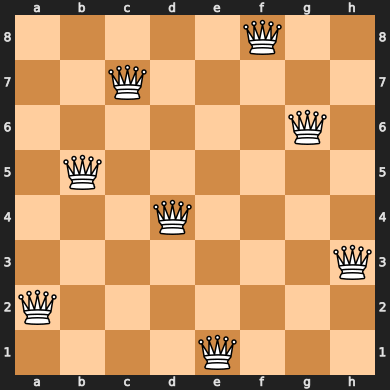

In [ ]:
board = chess.Board("5Q2/2Q5/6Q1/1Q6/3Q4/7Q/Q7/4Q3 w - - 0 1")
display(board)

# Subida da encosta

[Subida da encosta](https://en.wikipedia.org/wiki/Hill_climbing) é um algoritmo iterativo que opera localmente sobre uma região do espaço de busca e cuja aplicação em um problema depende da definição de:

1. [uma representação dos estados do problema](#scrollTo=JVlg5smptuZD&line=7&uniqifier=1),
2. [uma vizinhança](#scrollTo=O_tWjqWLEA8o&line=8&uniqifier=1) e
3. [uma função de avaliação de estado](#scrollTo=rurQj4gafdm_&line=7&uniqifier=1).

Esses pontos são descutidos a seguir.

## Representação de estados

Na representação adotada, cada estado é um vetor $v$ de $N$ posições que armazena a posição ocupada em cada linha do tabuleiro.

Para cada linha $i, 0 \leq i \lt N$, $v[i]$ contém um número inteiro $j, 1 \leq j \leq N$, que indica a coluna ocupada pela dama.

O vetor a seguir é o estado da [Figura acima](#scrollTo=iuXyoJC9rVNq&line=1&uniqifier=1).


$$\begin{bmatrix} 6 & 3 & 7 & 2 & 4 & 8 & 1 & 5\end{bmatrix}$$

O número $6$ na primeira posição indica que há uma dama na sexta coluna da primeira linha do tabuleiro. Isso também vale para as demais linhas do tabuleiro e posições do vetor. Os números $3$ e $7$ indicam que na segunda e terceira linha a dama ocupa a terceira e sétima coluna.

## Visualização de estados

A função `mostrar_tabuleiro` recebe um estado $s$ com 8 posições e desenha o tabuleiro representado em $s$.

> **Não utilize essa função para $N$ diferente de 8.** `mostrar_tabuleiro`espera um estado com $8$ damas.

In [ ]:
def fen_regras(s):
	return ("Q7" if s == 1 else
          "7Q" if s == 8 else
          "{}".format(s-1) + "Q" + "{}".format(8-s))

def fen(estado):
    return "/".join(map(fen_regras, estado))+' w - - 0 1'

def mostrar_tabuleiro(estado):
  board = chess.Board(fen(estado))
  display(board)

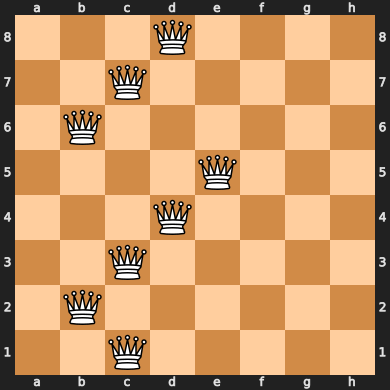

In [ ]:
estado = np.array([4,3,2,5,4,3,2,3])
mostrar_tabuleiro(estado)

## Avaliação de estados  

A função de avaliação mede a *qualidade* de uma solução.

Para as _N_ damas, uma função possível é o número de pares de damas que se atacam.
Uma ataque acontece quando duas damas quaisquer ocupam uma mesma linha, coluna ou diagonal.
Quanto menor a avaliação melhor é o estado. O melhor estado (mínimo global) possui avaliação zero.  

O código a seguir calcula o número de ataques levando em conta a representação vetorial das linhas. Como as damas nunca ocupam uma mesma linha, é preciso verificar apenas os ataques na coluna e diagonal.

*Ataque na coluna*

> Se $v[i]$ é igual à $v[j]$, então as dama nas linha $i$ e $j$ estão na mesma coluna.  


*Ataque na diagonal*

> Se $v[i]$ é igual à $v[j] \pm (j-i)$, então as damas nas linha $i$ e $j$ estão na mesma diagonal.

In [ ]:
def ataque(v, i, j):
  return (1 if v[i] == v[j] or v[i] - (j-i) == v[j] or v[i] + (j-i) == v[j] else
          0)

def contar_ataques_dama_i(v, i):
  return sum([ataque(v, i, j) for j in range(i+1, len(v))])


def avaliar(v):
  return sum([contar_ataques_dama_i(v, i) for i in range(len(v))])


## Vizinhança

A vizinhaça de um estado é definida aplicando a seguinte definição

> Um estado $u$ é vizinho de um estado $s$ se e somente apenas uma dama em $u$ está em uma posição diferente das damas em $s$.

Para gerar um estado vizinho é

Cada estado possui portanto $8\times7 = 56$ estados vizinhos.

A função `encontrar_vizinhos` recebe um estado e devolve uma lista com todos os seus vizinhos.



In [ ]:
from numpy import concatenate as concat

# A funcao vizinho_k_i recebe um estado, uma posicao i e um valor k
# e devolve um novo estado com o valor k na posicao i
def vizinho_k_i(estado, i, k):
  return concat( (estado[0:i], np.array([k]), estado[i+1::]))

# A funcao vizinhos_i recebe um estado e uma posicao i de uma dama
# e devolve uma lista com todos os vizinhos de i.
# Cada novo estado altera o valor na posicao i para todos os valores possiveis
def vizinhos_i(estado, i):
  return [vizinho_k_i(estado, i, k) for k in range(1,estado.size+1) if k!=estado[i] ]

# A funcao recebe um estado e devolve uma lista com todos os estados vizinhos.
def listar_vizinhos(estado):
  return [x for list in [(vizinhos_i(estado, i)) for i in range(estado.size)] for x in list]


Considere o estado abaixo

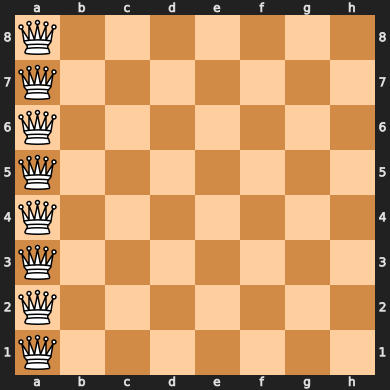

In [ ]:
estado = np.array([1, 1, 1, 1, 1, 1, 1, 1])
mostrar_tabuleiro(estado)

As Figuras abaixo mostram dois de seus vizinhos. Observe que apenas a dama na primeira linha mudou de posição.

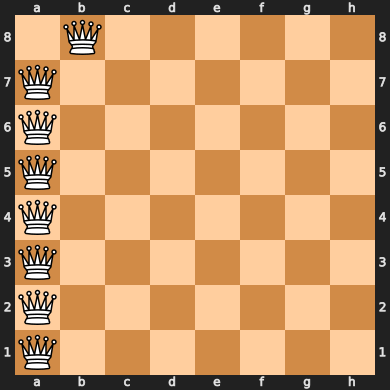

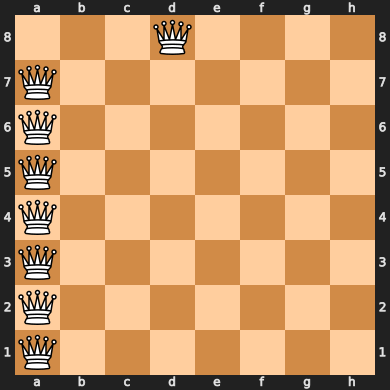

In [ ]:

vizinhos = listar_vizinhos(estado)
mostrar_tabuleiro(vizinhos[0])
mostrar_tabuleiro(vizinhos[2])

## Implementação


O código abaixo implementa o algoritmo utilizando as funções `encontrar_vizinhos` e `avaliar`. Observe que algoritmo nem sempre encontra um mínimo global.

Numero de ataques da solução encontrada:  0
Numero iterações:  4
[7 4 2 8 6 1 3 5]


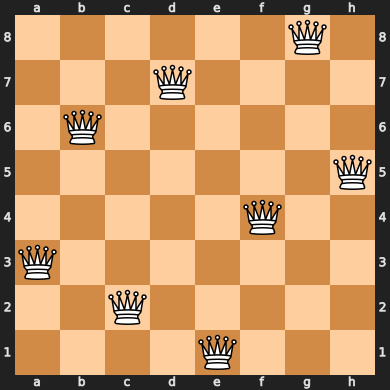

In [ ]:
def subida_encosta(N, max_iter):

  melhor_estado = np.array(np.random.randint(1, N, N)) # estado inicial aleatório
  val_melhor = avaliar(melhor_estado) #valor da função de avaliação para o melhor estado até o momento

  it = 0

  while it < max_iter:

    estados_vizinhos = listar_vizinhos(melhor_estado)
    vals = [avaliar(estado) for estado in estados_vizinhos]
    val_melhor_vizinho = np.min(vals)

    if val_melhor_vizinho < val_melhor:
      val_melhor = val_melhor_vizinho
      melhor_estado = estados_vizinhos[np.argmin(vals)]
    else:
        break

    it = it + 1

  return val_melhor, melhor_estado, it

# Número de damas
N = 8

val_melhor, melhor_estado, it = subida_encosta(N, 50)
print("Numero de ataques da solução encontrada: ", val_melhor)
print("Numero iterações: ", it)
print(melhor_estado)

if N==8:
  mostrar_tabuleiro(melhor_estado)

# Têmpera Simulada - Simulated annealing

[Têmpera Simulada](https://pt.wikipedia.org/wiki/Simulated_annealing) é um algoritmo de busca probabilístico inspirado na termodinâmica. Ele opera localmente no espaço de busca e, ocasionalmente, aceita soluções piores para escapar de mínimos locais e ampliar a exploração. O algoritmo reduz gradualmente a probabilidade de aceitar soluções inferiores, simulando o resfriamento de um material até alcançar um estado estável.

Novamente, um estado vizinho é aquele com apenas uma rainha em uma posição diferente.
A função `gerar_vizinho` recebe um estado e modifica aleatoriamente a posição de apenas uma rainha.


In [ ]:
import random

def gerar_vizinho(estado):
    """Gera um estado vizinho modificando a posição de uma rainha aleatória."""
    n = len(estado)
    vizinho = estado[:]
    linha = random.randint(1, n)
    nova_coluna = random.randint(1, n)
    while nova_coluna == vizinho[linha-1]:  # Evita que a nova coluna seja igual à atual
        nova_coluna = random.randint(1, n )
    vizinho[linha-1] = nova_coluna
    return vizinho

O código abaixo implementa o algoritmo para o problema das $N$-rainhas usando a função `avaliar`.

Numero de ataques:  0
Solução encontrada: [5, 7, 1, 4, 2, 8, 6, 3]


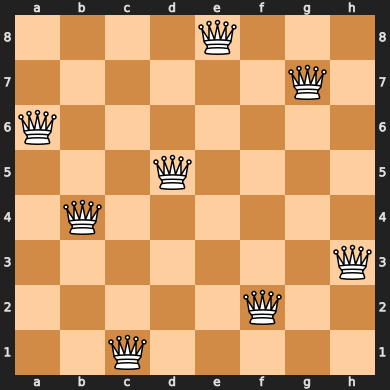

In [ ]:
import random
import math


def tempera_simulada(tamanho_tabuleiro, temperatura_inicial, taxa_resfriamento):
    """Resolve o problema das N rainhas usando Têmpera Simulada."""
    estado_atual = [random.randint(1, tamanho_tabuleiro) for _ in range(tamanho_tabuleiro)]
    temperatura = temperatura_inicial

    while temperatura > 0.01:
        conflitos_atual = avaliar(estado_atual)
        if conflitos_atual == 0:  # Solução encontrada
            return (estado_atual, 0)

        estado_vizinho = gerar_vizinho(estado_atual)
        conflitos_vizinho = avaliar(estado_vizinho)

        # Probabilidade de aceitar o novo estado
        delta_conflitos = (conflitos_vizinho - conflitos_atual)
        if delta_conflitos < 0 or random.uniform(0, 1) < math.exp(-delta_conflitos / temperatura):
            estado_atual = estado_vizinho

        # Resfria a temperatura
        temperatura *= taxa_resfriamento

    return (estado_atual, conflitos_vizinho)  # Retorna None se não encontrou solução

# Parâmetros
N = 8
temperatura_inicial = 100
taxa_resfriamento = 0.99

# Resolução
solucao, conflitos = tempera_simulada(N, temperatura_inicial, taxa_resfriamento)

print("Numero de ataques: ", conflitos)
print("Solução encontrada:", solucao)

if N==8:
  mostrar_tabuleiro(solucao)


# Algoritmo Genético

[Algoritmo genético](https://pt.wikipedia.org/wiki/Algoritmo_gen%C3%A9tico) é uma técnica de busca que opera localmente sobre múlltiplas regiões do espaço de busca ao mesmo tempo e cuja aplicação depende da definição de:

1. uma representação vetorial dos estados do problema e
2. uma função de avaliação de estado.

Seus passos principais são:

1. definir um população inicialmente aleatória - amostras de diferentes regiões do espaço de busca,
2. selecionar aleatóriamente os melhores indivíduos da população,
3. realizar o cruzamento entre os indivíduos selecionados e
4. realizar uma mutação aleatória


O código abaixo implementa esses passos para o problema das _N_ damas utilizando o [mesmo esquema de representação](#scrollTo=JVlg5smptuZD&line=7&uniqifier=1) e [função avaliação](#scrollTo=rurQj4gafdm_&line=7&uniqifier=1)  do exemplo anterior.

Nessa implementação, a seleção de indíviduos para o cruzamento é realizada levando em conta o valor da avaliação. A probabilidade de seleção de um indivíduo $\text{ind}$ é dada por:

\begin{equation}
P(ind) = \frac{1}{ \textrm{avaliar}(\text{ind}) + 1},
\end{equation}
em que $\textrm{avaliar}$ é a função avalição. Quanto menor o valor de `avaliar`, maior será a chance de um indivíduo ser selecionado.



Numero de ataques da solução encontrada:  0
Numero iterações:  70
[4 7 1 8 5 2 6 3]


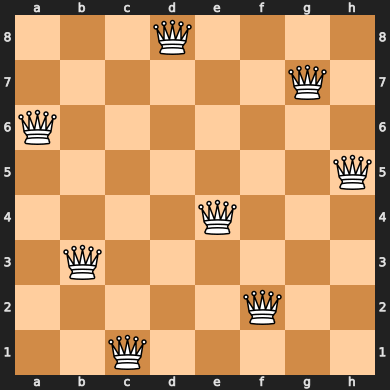

In [ ]:
import random
from numpy import concatenate as concat

def cruzamento(ind1, ind2, N, k):
  return concat((ind1[0:k],ind2[k:N]))

def mutacao(ind, prob_mutacao, g, v, N):
  return (ind if np.random.random() > prob_mutacao else
          concat( (ind[0:g], np.array([v]), ind[g+1:N]) ) )


def algoritmo_genetico(N, tam_pop, prob_mutacao, max_iter):

  #populacao inicial - uma lista de _tam_pop_ numpy arrays aleatorios. cada numpy array tem tamanho N e contém números no intervalo [1 a N+1]
  pop = [np.random.randint(1, N+1, N) for i in range(tam_pop)]

  aval = [avaliar(ind) for ind in pop]
  melhor_valor = min(aval)
  melhor_ind = np.argmin(aval)

  it = 0

  while it < max_iter:

    # Seleção
    # A selecao é um processo aleatorio que escolhe os pares para o cruzamento
    # A probalidade de selecao leva em conta o valor devolvido por avaliar
    # Como o melhor valor é zero é necessario inverter a função 1/(avaliar(individuo)+1)
    ap =[(lambda x: 1/(x+1))(x) for x in aval]
    pop = random.choices(pop, ap, k=tam_pop)

    #Cruzamento
    k = np.random.randint(1, N)
    npop = [cruzamento(pop[i],pop[i+1], N, k) for i in range(0, tam_pop-1, 2) ] + [cruzamento(pop[i+1], pop[i], N, k) for i in range(0, tam_pop-1, 2) ]

    #mutacao
    npop = [mutacao(ind, prob_mutacao, np.random.randint(0, N), np.random.randint(1, N+1), N) for ind in npop]

    pop = npop

    aval = list(map(avaliar, pop))
    melhor_valor = min(aval)
    melhor_ind = np.argmin(aval)

    if melhor_valor == 0:
      break

    it = it + 1

  return pop[melhor_ind], melhor_valor, it

# Quantidade de Damas
N=8

melhor_estado, melhor_valor, it = algoritmo_genetico(N, 100, 0.5, 1000)
print("Numero de ataques da solução encontrada: ", melhor_valor)
print("Numero iterações: ", it)
print(melhor_estado)

if N == 8:
  mostrar_tabuleiro(melhor_estado)

## Implementação com PyGAD

Nesta seção, apresentamos uma solução usando a biblioteca de algoritmo genético e otimização em aprendizado de máquina **PyGAD**.

PyGAD suporta diferentes tipos de operadores de crossover, mutação e seleção de pais. PyGAD permite que diferentes tipos de problemas sejam otimizados usando o algoritmo genético personalizando a função de aptidão. Ela funciona com problemas de otimização de objetivo único e multiobjetivo.


Instalando o pacote PyGAD

In [ ]:
!pip3 install pygad


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.6/89.6 kB 3.2 MB/s eta 0:00:00


O código abaixo é uma implementação com fitness construída aproveitando a função avaliar.



In [ ]:
import pygad


def fitness_func(ga_instance, solution, solution_idx):
    fitness = 1.0 / (avaliar(solution) + 0.000001)  # Evitar divisão por zero
    return fitness

# Número de damas
N = 9

# Configuração do GA
num_generations = 100
num_parents_mating = 2
sol_per_pop = 100
num_genes = N

# Faixa de valores dos genes
init_range_low = 1
init_range_high = N+1  # Exclusivo, garantindo que os valores sejam de 1 a 8

parent_selection_type = "rws"  # Seleção por roleta
keep_parents = 1
crossover_type = "single_point"
mutation_type = "random"
mutation_percent_genes = 14

ga_instance = pygad.GA(
    num_generations=num_generations,
    num_parents_mating=num_parents_mating,
    fitness_func=fitness_func,
    sol_per_pop=sol_per_pop,
    num_genes=num_genes,
    init_range_low=init_range_low,
    init_range_high=init_range_high,
    parent_selection_type=parent_selection_type,
    keep_parents=keep_parents,
    crossover_type=crossover_type,
    mutation_type=mutation_type,
    mutation_percent_genes=mutation_percent_genes,
    random_mutation_min_val=1,
    random_mutation_max_val=N,
    gene_space = range(1,N+1),
    gene_type=int
)


ga_instance.run()

solution, solution_fitness, solution_idx = ga_instance.best_solution()
print(f"Melhor Solução: {solution}")
print(f"Valor de Fitness da solução = {solution_fitness}")
print(f"Quantidade de Ataques da solução = {avaliar(solution)}")

if N == 8:
  mostrar_tabuleiro(solution)

Melhor Solução: [6 4 9 1 5 2 8 3 7]
Valor de Fitness da solução = 1000000.0
Quantidade de Ataques da solução = 0


# Exercício (2.0 pontos)

1. Como os parâmetros do Algoritmo Genetico afetam a otimização? Crie uma explicação baseada no *tradeoff* entre **explore-exploit** e descreva o que você faria se os parâmetros iniciais do algoritmo genético não funcionarem. Use o exemplo anterior do Pygad para mostrar na prática.